# 🔬 科研计算环境 · 快速上手

本 Notebook 演示这套环境的核心能力（覆盖你原来在 MATLAB 里的绝大多数用法）。

**已安装的库**

| 类别 | 库 |
|---|---|
| 数值/矩阵 | `numpy`, `scipy` |
| 符号计算 | `sympy` |
| 数据分析 | `pandas` |
| 绘图 | `matplotlib`, `seaborn`, `plotly` |
| 机器学习 | `scikit-learn` |
| 图像处理 | `scikit-image` |
| 统计建模 | `statsmodels`, `uncertainties`, `lmfit` |
| 控制系统 | `control` |
| 加速/大数据 | `numba`, `h5py` |
| 交互控件 | `ipywidgets` |

> 运行方式：菜单 `Cell → Run All` 一次性跑完，或按 `Shift+Enter` 逐格运行。


## 1. 数值计算与线性代数（≈ MATLAB 矩阵运算）

In [1]:
import numpy as np
from scipy import linalg

A = np.array([[4, -2, 1],
              [-2, 4, -2],
              [1, -2, 3]], dtype=float)
b = np.array([11, -16, 17], dtype=float)

x = np.linalg.solve(A, b)          # 等价 MATLAB: A\b
print("方程组解 x =", np.round(x, 4))
print("特征值   =", np.round(linalg.eigvalsh(A), 4))
print("行列式   =", round(np.linalg.det(A), 4), " 秩 =", np.linalg.matrix_rank(A))

方程组解 x = [ 1.   -1.25  4.5 ]
特征值   = [1.3126 2.5684 7.119 ]
行列式   = 24.0  秩 = 3


## 2. 符号计算（≈ MATLAB symbolic toolbox）

In [2]:
import sympy as sp

x, y = sp.symbols('x y')
f = sp.sin(x) * sp.exp(-x)
print("求导  d/dx =", sp.diff(f, x))
print("积分  ∫    =", sp.integrate(f, x))
print("定积分 0..pi =", sp.integrate(sp.sin(x), (x, 0, sp.pi)))
print("解方程      =", sp.solve(x**2 - 5*x + 6, x))
print("化简        =", sp.simplify(sp.sin(x)**2 + sp.cos(x)**2))

求导  d/dx = -exp(-x)*sin(x) + exp(-x)*cos(x)


积分  ∫    = -exp(-x)*sin(x)/2 - exp(-x)*cos(x)/2
定积分 0..pi = 2
解方程      = [2, 3]
化简        = 1


## 3. 数值积分 / 微分方程 / 最优化

In [3]:
from scipy import integrate, optimize

# 数值积分
I, err = integrate.quad(lambda t: np.exp(-t) * np.sin(3*t), 0, np.pi)
print(f"∫ e^-t sin(3t) dt = {I:.6f}")

# 常微分方程：阻尼振动 y'' + 0.5 y' + 4 y = 0
sol = integrate.solve_ivp(lambda t, y: [y[1], -0.5*y[1] - 4*y[0]],
                          [0, 10], [1, 0], t_eval=np.linspace(0, 10, 200))
print(f"ODE 求解：{sol.y.shape[1]} 个点，t=10 时 y = {sol.y[0, -1]:.5f}")

# 最优化
res = optimize.minimize(lambda v: (v[0]-1)**2 + (v[1]-2)**2 + 3, [0, 0])
print(f"最小值点 = {np.round(res.x, 4)}，最小值 = {res.fun:.4f}")

∫ e^-t sin(3t) dt = 0.312964
ODE 求解：200 个点，t=10 时 y = 0.05305
最小值点 = [1. 2.]，最小值 = 3.0000


## 4. 信号处理（FFT / 滤波）

In [4]:
from scipy import signal, fft

fs = 1000
t = np.arange(0, 1, 1/fs)
sig = 2*np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t) + 0.3*np.random.randn(len(t))

# 巴特沃斯低通滤波，截止 80 Hz
sos = signal.butter(6, 80, btype='low', fs=fs, output='sos')
sig_f = signal.sosfiltfilt(sos, sig)

Y = np.abs(fft.rfft(sig))
freq = fft.rfftfreq(len(sig), 1/fs)
top = freq[np.argsort(Y)[-3:]][::-1]
print("信号中最强的三个频率:", np.round(top, 1), "Hz")
print("滤波后高频残余能量:", round(np.sum(np.abs(fft.rfft(sig_f))[freq > 150]), 2))

信号中最强的三个频率: [ 50. 120. 310.] Hz
滤波后高频残余能量: 74.93


## 5. 统计与数据表格（≈ MATLAB table / statistics）

In [5]:
import pandas as pd
from scipy import stats

np.random.seed(0)
group_a = np.random.normal(12.0, 0.3, 30)
group_b = np.random.normal(12.4, 0.35, 30)

t_stat, p_val = stats.ttest_ind(group_a, group_b)
print(f"独立样本 t 检验: t = {t_stat:.4f}, p = {p_val:.4f}")

df = pd.DataFrame({"A": group_a, "B": group_b})
print(df.describe().round(4))

独立样本 t 检验: t = -1.9755, p = 0.0530
             A        B
count  30.0000  30.0000
mean   12.1329  12.2987
std     0.3301   0.3200
min    11.2341  11.7067
25%    11.9582  12.0873
50%    12.1216  12.2756
75%    12.4006  12.4931
max    12.6809  13.0828


## 6. 机器学习（≈ MATLAB Statistics & ML Toolbox）

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

X, y = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
clf = RandomForestClassifier(n_estimators=100, random_state=0).fit(Xtr, ytr)
pred = clf.predict(Xte)
print(f"随机森林分类准确率 = {accuracy_score(yte, pred):.3f}")
print("混淆矩阵:\n", confusion_matrix(yte, pred))

随机森林分类准确率 = 0.978
混淆矩阵:
 [[16  0  0]
 [ 0 17  1]
 [ 0  0 11]]


## 7. 绘图（matplotlib / seaborn）

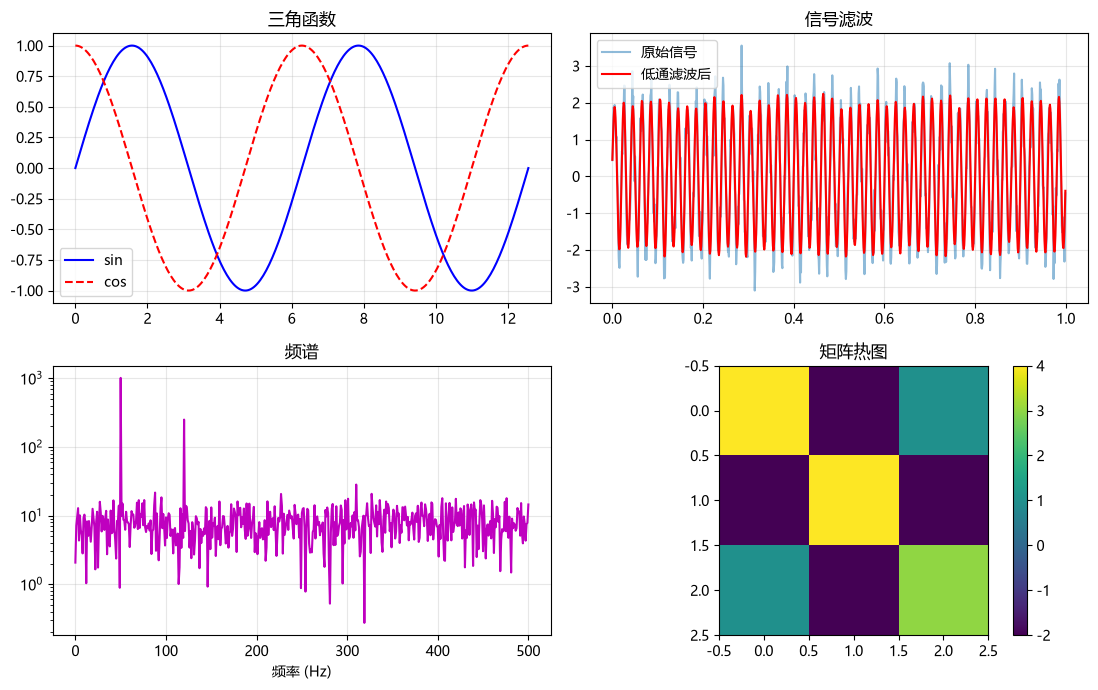

图已保存为 starter_demo.png


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']   # 中文正常显示
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(2, 2, figsize=(11, 7))

xx = np.linspace(0, 4*np.pi, 300)
ax[0,0].plot(xx, np.sin(xx), 'b-', label='sin')
ax[0,0].plot(xx, np.cos(xx), 'r--', label='cos')
ax[0,0].set_title('三角函数'); ax[0,0].legend(); ax[0,0].grid(alpha=.3)

ax[0,1].plot(t, sig, alpha=.5, label='原始信号')
ax[0,1].plot(t, sig_f, 'r-', lw=1.5, label='低通滤波后')
ax[0,1].set_title('信号滤波'); ax[0,1].legend(); ax[0,1].grid(alpha=.3)

ax[1,0].semilogy(freq, Y, 'm-')
ax[1,0].set_title('频谱'); ax[1,0].set_xlabel('频率 (Hz)'); ax[1,0].grid(alpha=.3)

im = ax[1,1].imshow(A, cmap='viridis')
ax[1,1].set_title('矩阵热图'); fig.colorbar(im, ax=ax[1,1])

plt.tight_layout()
plt.savefig('starter_demo.png', dpi=120, bbox_inches='tight')
plt.show()
print("图已保存为 starter_demo.png")

## 8. 下一步

- 改成你自己的数据/公式即可开始工作
- 需要新库时（受限网络下）：
  ```
  python download_wheels.py 包名 --dest wheels
  python -m pip install --no-index --find-links wheels 包名
  ```
- MATLAB 语法 → Python 对照：见 `MATLAB对照手册.md`
